In [1]:
import site
import sys
import subprocess
import os

# 1. Registrar la ruta de paquetes del usuario en el sistema
user_site = '/headless/.local/lib/python3.12/site-packages'
if os.path.exists(user_site):
    site.addsitedir(user_site)

# 2. Intentar importar; si falla, instalarlo automáticamente
try:
    from PyLTSpice import RawRead
    print('¡PyLTSpice ya estaba instalado y listo para usar!')
except ImportError:
    print('PyLTSpice no fue encontrado. Instalando automáticamente...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--user', 'PyLTSpice'])
    if os.path.exists(user_site):
        site.addsitedir(user_site)
    from PyLTSpice import RawRead
    print('¡PyLTSpice se instaló e importó correctamente!')

¡PyLTSpice ya estaba instalado y listo para usar!


<>:108: SyntaxWarning: invalid escape sequence '\m'
<>:109: SyntaxWarning: invalid escape sequence '\s'
<>:110: SyntaxWarning: invalid escape sequence '\s'
<>:108: SyntaxWarning: invalid escape sequence '\m'
<>:109: SyntaxWarning: invalid escape sequence '\s'
<>:110: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_561/1279086407.py:108: SyntaxWarning: invalid escape sequence '\m'
  plt.axvline(mu, color='red', linestyle='dashed', linewidth=1.5, label=f'Media ($\mu$): {mu:.4f}')
/tmp/ipykernel_561/1279086407.py:109: SyntaxWarning: invalid escape sequence '\s'
  plt.axvline(mu - 3*sigma, color='green', linestyle='dotted', linewidth=1.5, label=f'-3$\sigma$: {mu-3*sigma:.4f}')
/tmp/ipykernel_561/1279086407.py:110: SyntaxWarning: invalid escape sequence '\s'
  plt.axvline(mu + 3*sigma, color='green', linestyle='dotted', linewidth=1.5, label=f'+3$\sigma$: {mu+3*sigma:.4f}')


✓ Limpieza completada: Se retuvieron 129 iteraciones válidas de 215 totales.


,Dropout (mV),Margen Fase (Deg),UGB (Hz),Overshoot (mV),Undershoot (mV),Line Reg (mV),Load Reg (mV),PSRR 1k (dB),PSRR 10k (dB),Voltaje de salida en line (V),Voltaje de salida en tran (V)
0,29.8931,78.6446,303372.0,0.264,8.702,0.345,0.559,56.3912,55.2336,1.18915,1.19494
1,30.7190,79.0524,305828.0,0.261,8.570,0.322,0.557,61.3950,58.5844,1.18133,1.19564
2,30.8548,79.2158,308354.0,0.263,8.700,0.329,0.559,53.6479,52.9417,1.18733,1.19131
3,30.2909,77.3674,293527.0,0.259,8.510,0.335,0.564,53.1958,52.5732,1.17807,1.18942
4,30.5834,77.0548,290946.0,0.261,8.687,0.335,0.563,112.0580,112.2920,1.19925,1.18529
5,30.3351,79.6111,311129.0,0.257,8.476,0.342,0.560,111.9400,112.1770,1.18757,1.18590
6,30.7186,79.7528,312607.0,0.264,8.730,0.339,0.558,71.5253,61.9149,1.18077,1.19459
7,30.4372,78.7977,304760.0,0.258,8.436,0.324,0.560,111.8160,112.0560,1.19045,1.19041
8,30.5217,78.6026,302728.0,0.261,8.703,0.336,0.558,61.4743,59.1110,1.18867,1.18100
9,30.5543,76.9662,290164.0,0.267,8.877,0.324,0.558,54.9383,54.3403,1.18222,1.19958


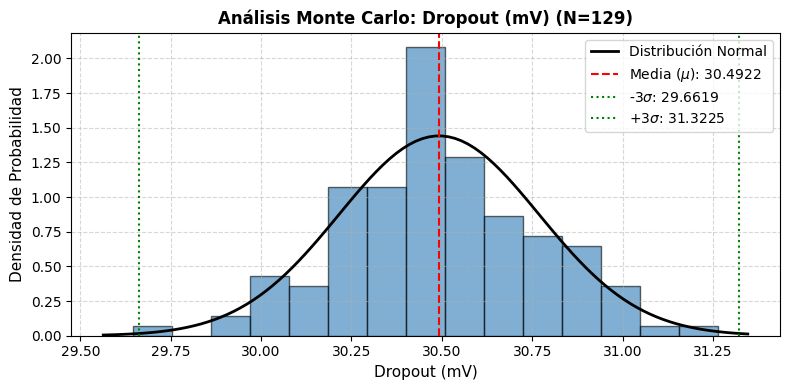

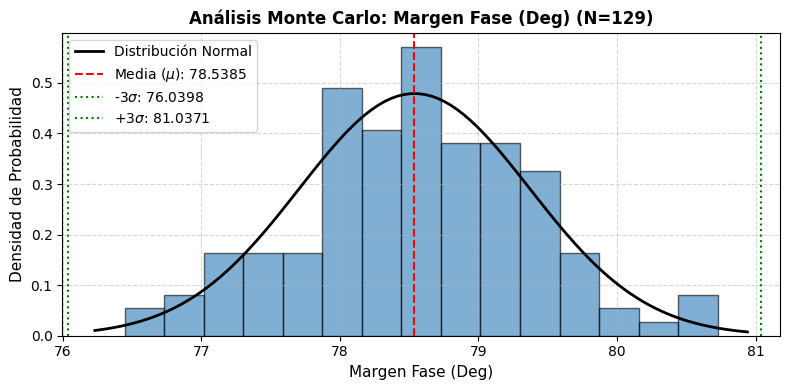

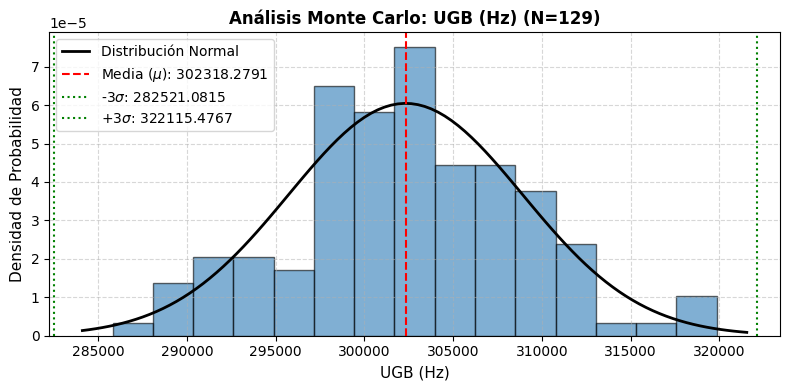

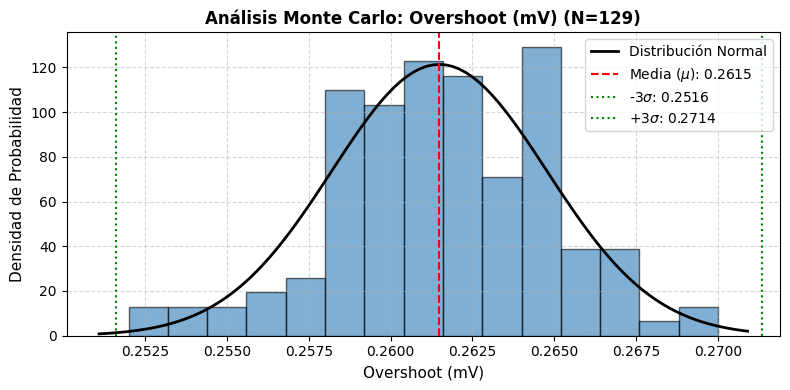

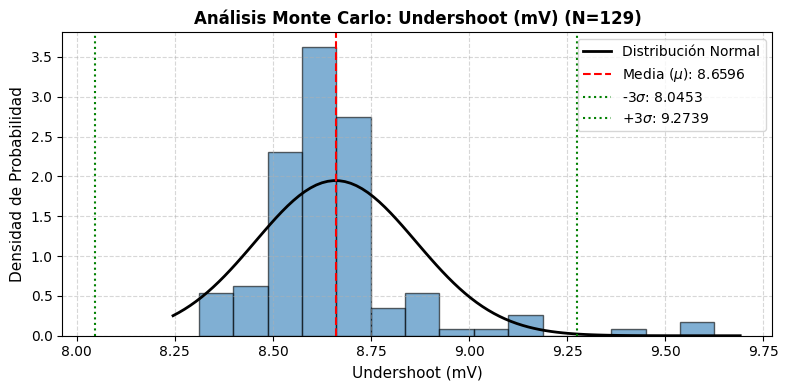

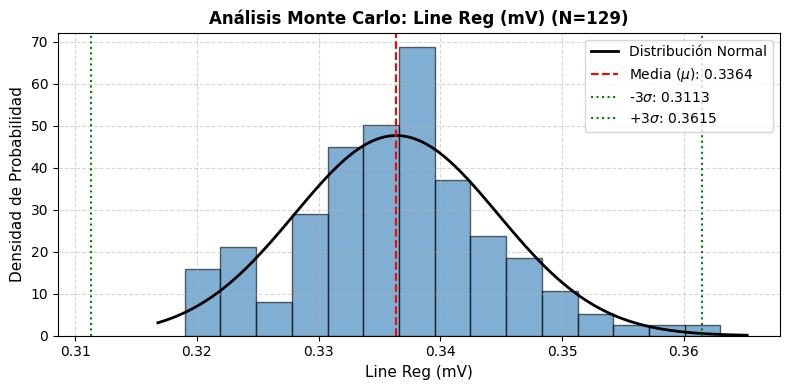

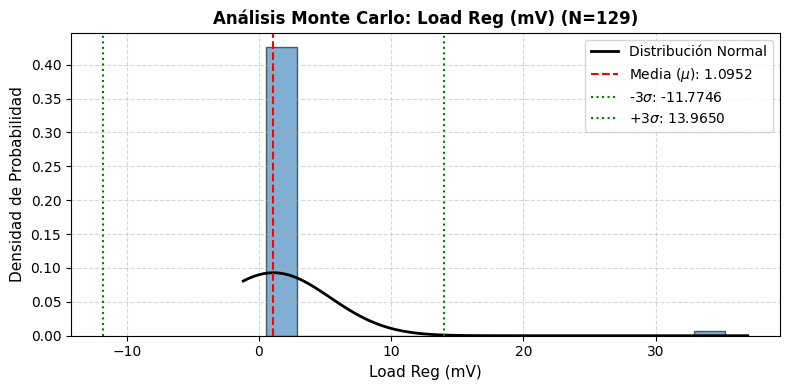

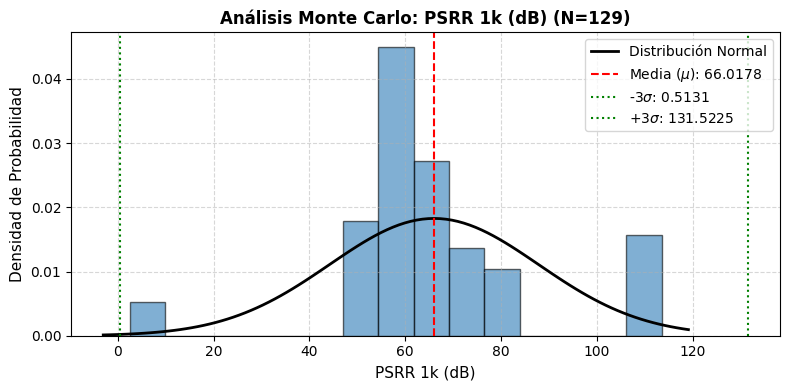

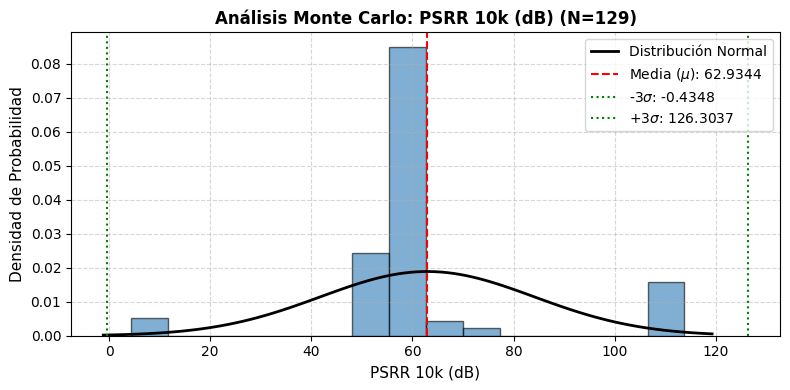

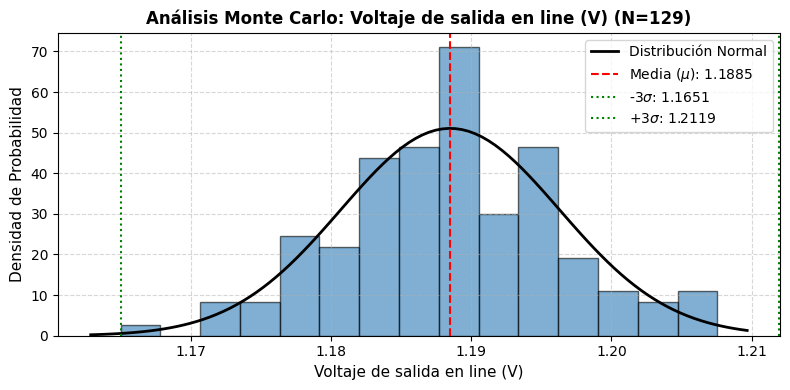

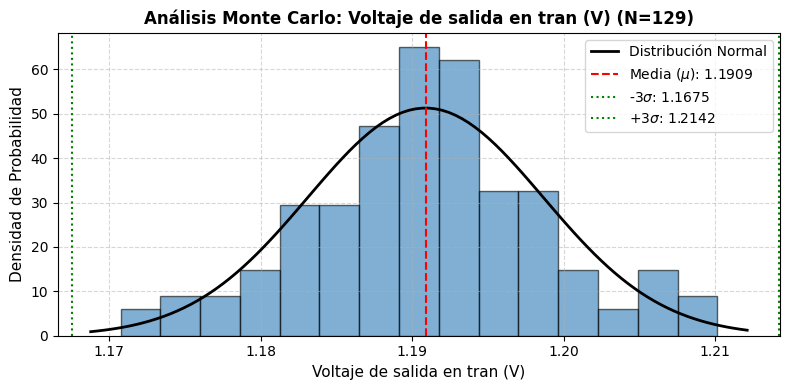

In [2]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import scipy.stats as stats
import os

# ==============================================================================
# 1. CARGAR Y EXTRAER LOS DATOS
# ==============================================================================
ruta_archivo = "/headless/.xschem/simulations/datos_mc.txt"

if not os.path.exists(ruta_archivo):
    print(f"⚠️ Archivo no encontrado en: {ruta_archivo}")
else:
    with open(ruta_archivo, 'r') as f:
        texto = f.read()

    # Función auxiliar para extraer números con Regex
    def extraer(variable, texto):
        patron = rf"{variable}\s*=\s*([\d\.\-eE\+]+)"
        encontrados = re.findall(patron, texto)
        
        resultados = []
        for x in encontrados:
            try:
                resultados.append(float(x))
            except ValueError:
                resultados.append(np.nan) 
                
        return resultados

    # Diccionario con TODOS los parámetros medidos en Ngspice
    datos_extraidos = {
        'Dropout (mV)': extraer('dropout_mV', texto),
        'Margen Fase (Deg)': extraer('margen_fase', texto),
        'UGB (Hz)': extraer('ugb', texto),
        'Overshoot (mV)': extraer('overshoot_mV', texto),
        'Undershoot (mV)': extraer('undershoot_mV', texto),
        'Line Reg (mV)': extraer('line_regulation_mv', texto),
        'Load Reg (mV)': extraer('load_regulation_mV', texto),
        'PSRR 1k (dB)': extraer('psrr_1k', texto),
        'PSRR 10k (dB)': extraer('psrr_10k', texto),
        'Voltaje de salida en line (V)': extraer('salida_line', texto),
        'Voltaje de salida en tran (V)': extraer('salida_tran', texto),
    }

    # Creamos el DataFrame
    df_mc = pd.DataFrame.from_dict(datos_extraidos, orient='index').T
    iteraciones_originales = len(df_mc)

    # ==============================================================================
    # 1.5. FILTRO DE CONVERGENCIA (LIMPIEZA DE DATOS)
    # ==============================================================================
    # a. Eliminar iteraciones con datos en blanco (NaN)
    df_mc = df_mc.dropna()
# Solo filtramos basuras matemáticas (valores fuera de los rieles de alimentación)
    if 'Voltaje de salida en tran (V)' in df_mc.columns:
        df_mc = df_mc[(df_mc['Voltaje de salida en tran (V)'] >= 0.0) & (df_mc['Voltaje de salida en tran (V)'] <= 1.8)]
    # b. Filtrar divergencias en el voltaje de salida transitorio


    # c. Filtrar divergencias en el voltaje de salida de línea
    if 'Voltaje de salida en line (V)' in df_mc.columns:
        df_mc = df_mc[(df_mc['Voltaje de salida en line (V)'] > 0) & (df_mc['Voltaje de salida en line (V)'] < 1.8)]

    # d. Filtrar anomalías transitorias extremas
    if 'Undershoot (mV)' in df_mc.columns:
        df_mc = df_mc[df_mc['Undershoot (mV)'] < 200]
        
    if 'Dropout (mV)' in df_mc.columns:
        df_mc = df_mc[df_mc['Dropout (mV)'] < 200]

    # e. Filtrar basuras matemáticas en las Regulaciones
    if 'Load Reg (mV)' in df_mc.columns:
        df_mc = df_mc[(df_mc['Load Reg (mV)'] > -50) & (df_mc['Load Reg (mV)'] < 50)]
        
    if 'Line Reg (mV)' in df_mc.columns:
        df_mc = df_mc[(df_mc['Line Reg (mV)'] > -50) & (df_mc['Line Reg (mV)'] < 50)]
        
    print(f"✓ Limpieza completada: Se retuvieron {len(df_mc)} iteraciones válidas de {iteraciones_originales} totales.")

    # Mostramos las primeras 10 corridas limpias
    try:
        display(df_mc.head(10)) 
    except NameError:
        print(df_mc.head(10))

# ==============================================================================
# 2. FUNCIÓN PARA GRAFICAR HISTOGRAMAS Y CAMPANA DE GAUSS
# ==============================================================================
def graficar_gauss(df, columna):
    datos = df[columna].dropna() 
    if len(datos) < 2: return
    
    mu = np.mean(datos)            
    sigma = np.std(datos, ddof=1)  
    
    plt.figure(figsize=(8, 4))
    
    count, bins, ignored = plt.hist(datos, bins=15, density=True, alpha=0.6, color='#2c7bb6', edgecolor='black')
    
    xmin, xmax = plt.xlim()
    x = np.linspace(xmin, xmax, 100)
    p = stats.norm.pdf(x, mu, sigma)
    plt.plot(x, p, 'k', linewidth=2, label='Distribución Normal')
    
    plt.axvline(mu, color='red', linestyle='dashed', linewidth=1.5, label=f'Media ($\mu$): {mu:.4f}')
    plt.axvline(mu - 3*sigma, color='green', linestyle='dotted', linewidth=1.5, label=f'-3$\sigma$: {mu-3*sigma:.4f}')
    plt.axvline(mu + 3*sigma, color='green', linestyle='dotted', linewidth=1.5, label=f'+3$\sigma$: {mu+3*sigma:.4f}')
    
    plt.title(f'Análisis Monte Carlo: {columna} (N={len(datos)})', fontsize=12, fontweight='bold')
    plt.xlabel(columna, fontsize=11)
    plt.ylabel('Densidad de Probabilidad', fontsize=11)
    plt.legend(loc='best')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    
    plt.show()

# ==============================================================================
# 3. GENERAR EL REPORTE VISUAL
# ==============================================================================
if 'df_mc' in locals() and not df_mc.empty:
    for columna in df_mc.columns:
        graficar_gauss(df_mc, columna)